# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [1]:
# If on colab, uncomment the following lines

# ! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]

print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35, random_state=42)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 19) (846,)
(549, 19) (549,) (297, 19) (297,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [3]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,822,95,41,82,170,65,9,145,46,19,145,163,314,140,64,4,8,199,207
1,486,104,57,103,222,72,12,221,30,25,177,223,718,218,72,11,12,186,195
2,182,91,42,66,169,66,7,145,44,19,140,169,325,159,67,4,0,201,207
3,375,109,52,95,189,58,4,227,29,25,158,262,776,217,82,0,19,187,186
4,528,95,47,73,195,70,7,167,38,20,152,184,430,185,69,9,19,200,206
5,223,81,44,72,139,60,6,153,44,19,146,180,347,178,81,1,15,182,186
6,840,93,34,66,140,56,7,130,51,18,120,151,251,114,62,5,29,201,207
7,593,89,43,77,147,54,8,144,46,19,146,163,308,174,64,13,5,194,201
8,346,117,52,110,228,65,12,212,31,24,163,228,668,220,66,21,25,194,205
9,357,109,49,109,193,59,10,207,32,24,156,225,635,213,70,13,31,191,202


Methods `describe` and `info` deliver some useful information.

In [4]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,425.723133,93.520947,44.675774,81.801457,168.204007,61.644809,8.457195,167.327869,41.273224,20.468124,147.438980,186.734062,431.540984,173.763206,72.158470,6.522769,12.646630,188.998179,195.854281
std,242.288797,8.063277,6.154680,15.928751,33.047995,7.110666,3.945857,32.506680,7.777590,2.526030,14.631309,30.436279,171.479332,31.793047,7.335198,4.980796,8.833356,6.298389,7.449629
min,0.000000,76.000000,33.000000,42.000000,104.000000,47.000000,2.000000,114.000000,26.000000,17.000000,118.000000,131.000000,191.000000,112.000000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,217.000000,87.000000,40.000000,70.000000,140.000000,57.000000,7.000000,146.000000,34.000000,19.000000,136.000000,167.000000,317.000000,148.000000,67.000000,2.000000,6.000000,184.000000,191.000000
50%,430.000000,93.000000,44.000000,79.000000,165.000000,61.000000,8.000000,157.000000,43.000000,20.000000,145.000000,177.000000,363.000000,173.000000,71.000000,6.000000,11.000000,189.000000,197.000000
75%,636.000000,99.000000,49.000000,98.000000,195.000000,66.000000,10.000000,196.000000,46.000000,23.000000,159.000000,216.000000,576.000000,196.000000,75.000000,10.000000,19.000000,193.000000,201.000000
max,845.000000,117.000000,59.000000,110.000000,306.000000,126.000000,52.000000,265.000000,59.000000,29.000000,186.000000,288.000000,1018.000000,268.000000,127.000000,22.000000,40.000000,206.000000,211.000000


In [5]:
X_train_pd.info()

<class 'pandas.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
 18  18      549 non-null    int64
dtypes: int64(19)
memory usage: 81.6 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [6]:
print(data[:10, 0])
print(np.all(data[:, 0] == np.arange(len(data))))

X_train = X_train[:, 1:]
X_test = X_test[:, 1:]
print(X_train.shape, X_test.shape)

print(pd.Series(y_train).value_counts())
print(np.round(X_train.std(axis=0), 1))

[0 1 2 3 4 5 6 7 8 9]
True
(549, 18) (297, 18)
opel    152
saab    133
van     132
bus     132
Name: count, dtype: int64
[  8.1   6.1  15.9  33.    7.1   3.9  32.5   7.8   2.5  14.6  30.4 171.3
  31.8   7.3   5.    8.8   6.3   7.4]


Первый столбец car_data.csv содержит номер строки. Это не признак. Поэтому я убираю этот столбец. Пропусков в данных нет. Классы примерно сбалансированы.

Признаки сильно отличаются по масштабу. Стандартное отклонение меняется от 2.5 до 171. Для логистической регрессии и PCA данные нужно стандартизировать. Стандартизация сделана через StandardScaler внутри Pipeline. Тогда на кросс-валидации среднее и дисперсия считаются только по обучающим фолдам. Деревьям масштаб не важен.

В train_test_split добавлен random_state=42 для воспроизводимости результатов.

#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

{'lr__C': 1000} 0.8
[0.636 0.74  0.793 0.789 0.798 0.8  ]
accuracy: 0.828
f1 macro: 0.821


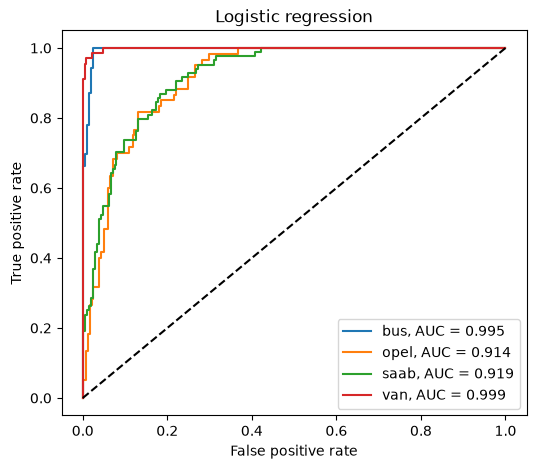

In [7]:
import warnings
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_curve, auc
from sklearn.base import clone


def print_scores(model, X, y):
    pred = model.predict(X)
    print('accuracy:', round(accuracy_score(y, pred), 3))
    print('f1 macro:', round(f1_score(y, pred, average='macro'), 3))


def plot_roc(model, X, y, title):
    proba = model.predict_proba(X)
    plt.figure(figsize=(6, 5))
    for k, cls in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(y == cls, proba[:, k])
        plt.plot(fpr, tpr, label=f'{cls}, AUC = {auc(fpr, tpr):.3f}')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.title(title)
    plt.legend()
    plt.show()


warnings.filterwarnings('ignore', category=ConvergenceWarning)

lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(solver='saga', tol=1e-3, max_iter=500, random_state=42)),
])
lr_grid = GridSearchCV(lr_pipe, {'lr__C': [0.01, 0.1, 1, 10, 100, 1000]}, cv=5, scoring='f1_macro')
lr_grid.fit(X_train, y_train)

print(lr_grid.best_params_, round(lr_grid.best_score_, 3))
print(np.round(lr_grid.cv_results_['mean_test_score'], 3))
print_scores(lr_grid, X_test, y_test)
plot_roc(lr_grid, X_test, y_test, 'Logistic regression')

В sklearn 1.8 параметр multi_class удалён. Для 4 классов multinomial используется по умолчанию. Поэтому параметр не передаётся. Метрика f1 считается с усреднением macro. Классы сбалансированы и все четыре класса одинаково важны.

Начиная с C = 1 качество на кросс-валидации почти не меняется и держится около 0.80. Регуляризация здесь почти не нужна. Признаков всего 18 на 549 объектов. При больших C solver saga не успевает сойтись за 500 итераций и выдаёт ConvergenceWarning. На качество это не влияет. Поэтому эти предупреждения отключены.

На тесте accuracy равна 0.83 и f1 равен 0.82. По ROC-кривым классы bus и van отделяются почти идеально с AUC больше 0.99. Для opel и saab AUC около 0.91. Это две легковые машины с похожими силуэтами. На путаницу между ними приходится 41 ошибка модели из 51.

In [8]:
# You might use this command to install scikit-plot. 
# Warning, if you a running locally, don't call pip from within jupyter, call it from terminal in the corresponding 
# virtual environment instead

# ! pip install scikit-plot

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot. 

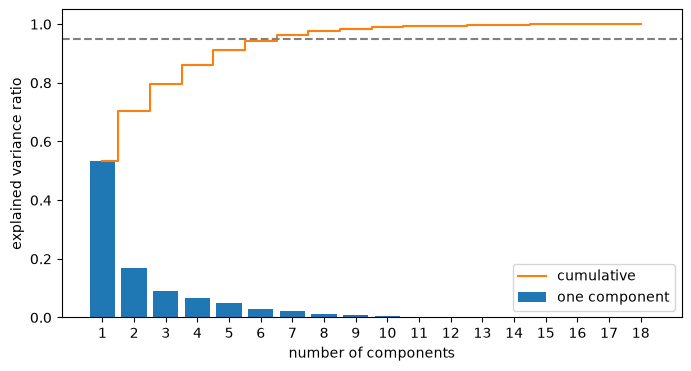

[0.534 0.703 0.794 0.862 0.911 0.941 0.962 0.976 0.984 0.989 0.993 0.995
 0.997 0.998 0.999 1.    1.    1.   ]


In [9]:
from sklearn.decomposition import PCA

scaler = StandardScaler().fit(X_train)
pca_full = PCA().fit(scaler.transform(X_train))
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_range = np.arange(1, len(cum_var) + 1)

plt.figure(figsize=(8, 4))
plt.bar(n_range, pca_full.explained_variance_ratio_, label='one component')
plt.step(n_range, cum_var, where='mid', color='C1', label='cumulative')
plt.axhline(0.95, color='gray', linestyle='--')
plt.xticks(n_range)
plt.xlabel('number of components')
plt.ylabel('explained variance ratio')
plt.legend()
plt.show()

print(np.round(cum_var, 3))

Первая компонента объясняет 53% дисперсии. Первые 7 компонент вместе объясняют 96%. Каждая следующая компонента добавляет меньше 1.5%.

#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

In [10]:
pca_raw = PCA().fit(X_train)
print('without scaling:', np.round(pca_raw.explained_variance_ratio_[:3], 3))
print('with scaling:   ', np.round(pca_full.explained_variance_ratio_[:3], 3))

n_components = int(np.argmax(cum_var >= 0.95)) + 1
print('n_components:', n_components)

pca = PCA(n_components=n_components).fit(scaler.transform(X_train))
X_train_pca = pca.transform(scaler.transform(X_train))
X_test_pca = pca.transform(scaler.transform(X_test))
print(X_train_pca.shape, X_test_pca.shape)

without scaling: [0.961 0.017 0.012]
with scaling:    [0.534 0.169 0.092]
n_components: 7
(549, 7) (297, 7)


Я беру минимальное число компонент с долей объяснённой дисперсии не меньше 95%. Получается 7 компонент.

Данные нужно нормировать. Без нормировки первая компонента объясняет 96% дисперсии только из-за признака SCALED VARIANCE ALONG MINOR AXIS. Разброс этого признака в десятки раз больше разброса остальных признаков. Первая компонента почти совпадает с ним.

StandardScaler и PCA обучаются только на train. К test применяется transform.

**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

{'lr__C': 10} 0.558
accuracy: 0.636
f1 macro: 0.624


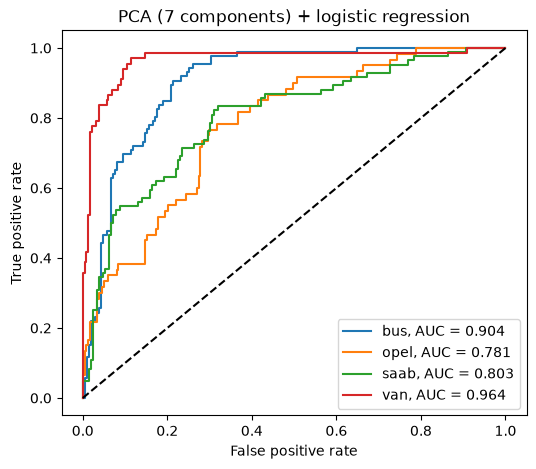

3 components, f1 (cv): 0.393


5 components, f1 (cv): 0.414
7 components, f1 (cv): 0.558
9 components, f1 (cv): 0.711


11 components, f1 (cv): 0.742


13 components, f1 (cv): 0.767
15 components, f1 (cv): 0.8


18 components, f1 (cv): 0.789


In [11]:
pca_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=n_components)),
    ('lr', LogisticRegression(solver='saga', tol=1e-3, max_iter=500, random_state=42)),
])
pca_grid = GridSearchCV(pca_pipe, {'lr__C': [0.01, 0.1, 1, 10, 100, 1000]}, cv=5, scoring='f1_macro')
pca_grid.fit(X_train, y_train)

print(pca_grid.best_params_, round(pca_grid.best_score_, 3))
print_scores(pca_grid, X_test, y_test)
plot_roc(pca_grid, X_test, y_test, f'PCA ({n_components} components) + logistic regression')

from sklearn.model_selection import cross_val_score

for n in [3, 5, 7, 9, 11, 13, 15, 18]:
    model = clone(pca_grid.best_estimator_).set_params(pca__n_components=n)
    score = cross_val_score(model, X_train, y_train, cv=5, scoring='f1_macro').mean()
    print(n, 'components, f1 (cv):', round(score, 3))

На 7 компонентах качество сильно падает. f1 на тесте равен 0.62. Без PCA было 0.82.

Перебор числа компонент на кросс-валидации показывает рост качества почти до конца. 7 компонент дают 0.56. 15 компонент дают 0.80. PCA сохраняет направления с наибольшим разбросом. Часть информации о классах лежит в направлениях с маленьким разбросом. В этой задаче PCA не нужен. Признаков и так немного.

#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

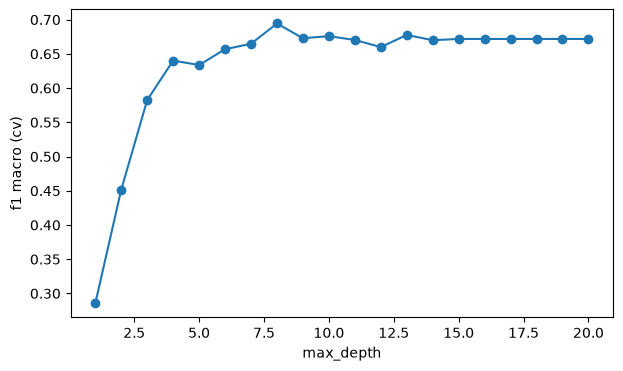

{'max_depth': 8} 0.694
accuracy: 0.721
f1 macro: 0.704


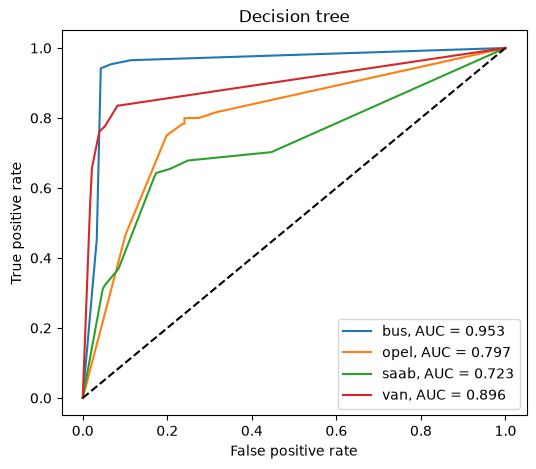

In [12]:
from sklearn.tree import DecisionTreeClassifier

tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': list(range(1, 21))},
    cv=5,
    scoring='f1_macro',
)
tree_grid.fit(X_train, y_train)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 21), tree_grid.cv_results_['mean_test_score'], marker='o')
plt.xlabel('max_depth')
plt.ylabel('f1 macro (cv)')
plt.show()

print(tree_grid.best_params_, round(tree_grid.best_score_, 3))
print_scores(tree_grid, X_test, y_test)
plot_roc(tree_grid, X_test, y_test, 'Decision tree')

Лучшая глубина равна 8 при f1 на CV 0.69. Более мелкое дерево недообучается. Более глубокое дерево начинает переобучаться. Качество на CV тогда перестаёт расти. На тесте accuracy равна 0.72 и f1 равен 0.70. Это заметно хуже логистической регрессии.

#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble? 

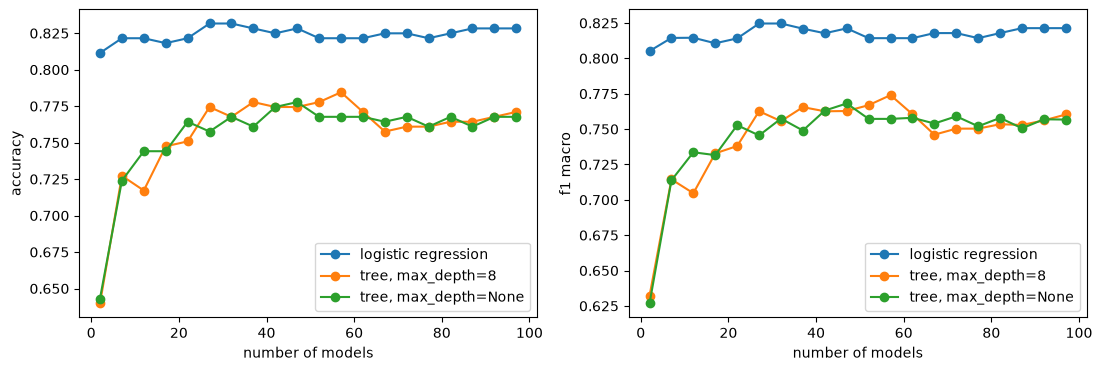

logistic regression | best f1: 0.825 at N = 27 | f1 at N = 97: 0.821
tree, max_depth=8 | best f1: 0.774 at N = 57 | f1 at N = 97: 0.76
tree, max_depth=None | best f1: 0.768 at N = 47 | f1 at N = 97: 0.757


In [13]:
n_max = 100
sizes = np.arange(2, n_max + 1, 5)

rng = np.random.default_rng(42)
bootstrap_idx = []
for _ in range(n_max):
    bootstrap_idx.append(rng.integers(0, len(X_train), len(X_train)))


def bagging_scores(base_model):
    probas = []
    for idx in bootstrap_idx:
        model = clone(base_model)
        model.fit(X_train[idx], y_train[idx])
        probas.append(model.predict_proba(X_test))
    classes = model.classes_
    acc = []
    f1 = []
    for n in sizes:
        pred = classes[np.mean(probas[:n], axis=0).argmax(axis=1)]
        acc.append(accuracy_score(y_test, pred))
        f1.append(f1_score(y_test, pred, average='macro'))
    return np.array(acc), np.array(f1)


def plot_scores(x, results, xlabel):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name, (acc, f1) in results.items():
        axes[0].plot(x, acc, marker='o', label=name)
        axes[1].plot(x, f1, marker='o', label=name)
    axes[0].set_ylabel('accuracy')
    axes[1].set_ylabel('f1 macro')
    for ax in axes:
        ax.set_xlabel(xlabel)
        ax.legend()
    plt.show()


bag_results = {
    'logistic regression': bagging_scores(lr_grid.best_estimator_),
    f'tree, max_depth={tree_grid.best_params_["max_depth"]}': bagging_scores(tree_grid.best_estimator_),
    'tree, max_depth=None': bagging_scores(DecisionTreeClassifier(random_state=42)),
}
plot_scores(sizes, bag_results, 'number of models')

for name, (acc, f1) in bag_results.items():
    print(name, '| best f1:', round(f1.max(), 3), 'at N =', sizes[f1.argmax()], '| f1 at N = 97:', round(f1[-1], 3))

По подсказке 100 бутстреп-выборок генерируются один раз. Ансамбль из N моделей усредняет вероятности первых N моделей.

Для деревьев качество растёт примерно до N от 25 до 40. Дальше качество выходит на плато около 0.76. На плато значение колеблется в пределах 0.01. Это от 1 до 3 объектов из 297 в тесте. Оптимальное N для деревьев лежит в диапазоне от 30 до 50. Большее число моделей качество не меняет. Бэггинг поднимает f1 дерева с 0.70 до 0.76.

Для логистической регрессии бэггинг почти ничего не даёт. Качество выходит на плато уже к N = 7 и дальше держится около 0.82. Оптимальное N здесь от 7 до 10. Логистическая регрессия мало меняется от выборки к выборке. Усреднение почти ничего не добавляет.

Гиперпараметры из 2.5 не обязаны быть оптимальными для ансамбля. Одиночное дерево ищет баланс между смещением и дисперсией. В бэггинге дисперсию снижает усреднение. Поэтому обычно берут более глубокие деревья. Я проверил деревья без ограничения глубины. На плато у обоих вариантов f1 от 0.75 до 0.77. Разница в пределах шума. Глубину стоит подбирать на кросс-валидации для самого ансамбля.

#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

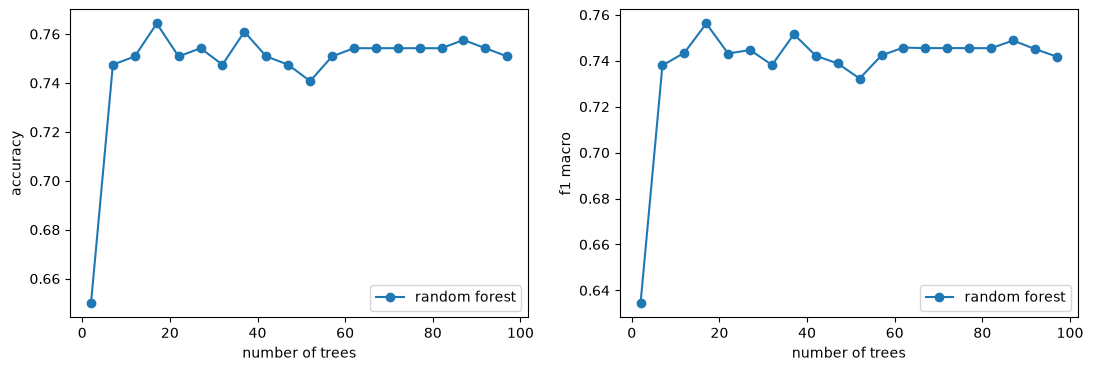

best f1: 0.756 at N = 17 | f1 at N = 97: 0.742


In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_acc = []
rf_f1 = []
for n in sizes:
    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    pred = rf.predict(X_test)
    rf_acc.append(accuracy_score(y_test, pred))
    rf_f1.append(f1_score(y_test, pred, average='macro'))
rf_acc = np.array(rf_acc)
rf_f1 = np.array(rf_f1)

plot_scores(sizes, {'random forest': (rf_acc, rf_f1)}, 'number of trees')
print('best f1:', round(rf_f1.max(), 3), 'at N =', sizes[rf_f1.argmax()], '| f1 at N = 97:', round(rf_f1[-1], 3))

Random forest выходит на плато уже к 10 или 20 деревьям с f1 около 0.75. Максимум 0.756 при 17 деревьях является шумом. Дальше качество колеблется в пределах 0.01. С 60 деревьев качество почти не меняется. Оптимальное число деревьев от 20 до 60. У бэггинга деревьев оптимум похожий и лежит от 30 до 50 моделей. Бэггингу логистических регрессий хватает от 7 до 10 моделей. Ансамбль им почти не нужен.

Качество леса здесь примерно равно качеству бэггинга деревьев глубины 8. Случайный выбор признаков почти не помогает. Вероятная причина в малом числе признаков. Их всего 18. Лучшей моделью остаётся логистическая регрессия.

#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it? 

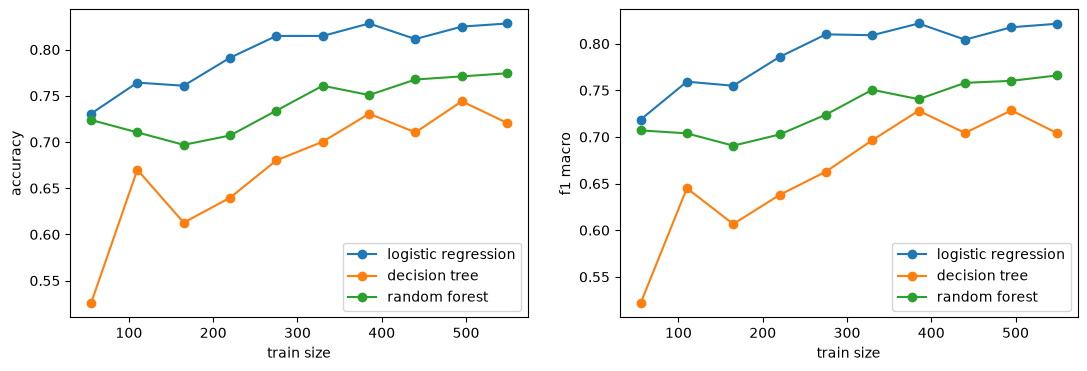

logistic regression | f1: [0.72 0.76 0.75 0.79 0.81 0.81 0.82 0.8  0.82 0.82]
decision tree | f1: [0.52 0.65 0.61 0.64 0.66 0.7  0.73 0.7  0.73 0.7 ]
random forest | f1: [0.71 0.7  0.69 0.7  0.72 0.75 0.74 0.76 0.76 0.77]


In [15]:
parts = np.array_split(np.random.default_rng(42).permutation(len(X_train)), 10)

curve_models = {
    'logistic regression': lr_grid.best_estimator_,
    'decision tree': tree_grid.best_estimator_,
    'random forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}
curve_results = {}
train_sizes = []
for name, base_model in curve_models.items():
    acc = []
    f1 = []
    train_sizes = []
    for k in range(1, 11):
        idx = np.concatenate(parts[:k])
        model = clone(base_model)
        model.fit(X_train[idx], y_train[idx])
        pred = model.predict(X_test)
        acc.append(accuracy_score(y_test, pred))
        f1.append(f1_score(y_test, pred, average='macro'))
        train_sizes.append(len(idx))
    curve_results[name] = (np.array(acc), np.array(f1))

plot_scores(train_sizes, curve_results, 'train size')
for name, (acc, f1) in curve_results.items():
    print(name, '| f1:', np.round(f1, 2))

Логистическая регрессия выходит на плато примерно на половине обучающей выборки. Это около 270 объектов. Дальше f1 держится около 0.82. Дополнительные данные ей почти не помогут.

Качество дерева сильно скачет от размера к размеру. Дерево сильно зависит от конкретной выборки. Random forest медленно растёт с 0.71 до 0.77. Дополнительные данные могут ещё немного улучшить лес.

На любом размере выборки лучшей моделью остаётся логистическая регрессия.

#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

best number of trees: 325


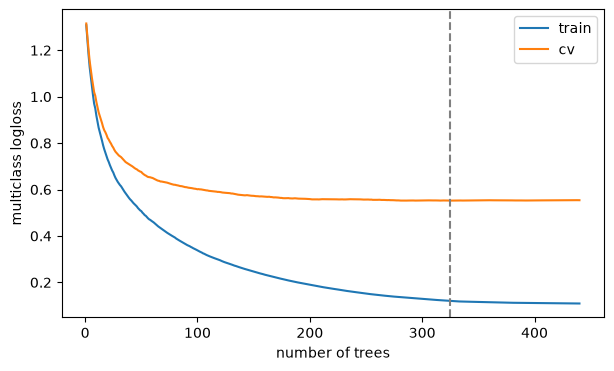

accuracy: 0.781
f1 macro: 0.775


In [16]:
from catboost import Pool, CatBoost, cv
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder().fit(y_train)
train_pool = Pool(X_train, encoder.transform(y_train))
test_pool = Pool(X_test, encoder.transform(y_test))

params = {
    'loss_function': 'MultiClass',
    'learning_rate': 0.1,
    'depth': 6,
    'random_seed': 42,
}
cv_results = cv(
    train_pool,
    params,
    iterations=1000,
    fold_count=5,
    early_stopping_rounds=50,
    stratified=True,
    seed=42,
    logging_level='Silent',
)
best_iterations = int(cv_results['test-MultiClass-mean'].idxmin()) + 1
print('best number of trees:', best_iterations)

plt.figure(figsize=(7, 4))
plt.plot(cv_results['iterations'] + 1, cv_results['train-MultiClass-mean'], label='train')
plt.plot(cv_results['iterations'] + 1, cv_results['test-MultiClass-mean'], label='cv')
plt.axvline(best_iterations, color='gray', linestyle='--')
plt.xlabel('number of trees')
plt.ylabel('multiclass logloss')
plt.legend()
plt.show()

boosting = CatBoost({**params, 'iterations': best_iterations, 'verbose': False})
boosting.fit(train_pool)
pred = encoder.inverse_transform(boosting.predict(test_pool, prediction_type='Class').ravel().astype(int))
print('accuracy:', round(accuracy_score(y_test, pred), 3))
print('f1 macro:', round(f1_score(y_test, pred, average='macro'), 3))

CatBoost используется через собственный API с классами Pool и CatBoost и функцией cv.

Число деревьев подбирается 5-fold кросс-валидацией с ранней остановкой. Обучение останавливается после 50 итераций без улучшения logloss на валидации. Минимум усреднённого по фолдам logloss достигается примерно при 325 деревьях. Параметры модели learning_rate 0.1 и depth 6. После этого logloss на train продолжает падать. На CV logloss перестаёт улучшаться. Значит модель начинает переобучаться.

На тесте accuracy равна 0.78 и f1 равен 0.78. Бустинг лучше одиночного дерева. Он также лучше бэггинга и случайного леса. Логистическая регрессия работает лучше бустинга.